# Simple ISIS accelerator test

### Imports

In [1]:
import sys
from pathlib import Path
import numpy as np 
import matplotlib.pyplot as plt
import xobjects as xo
import xpart as xp
from sim_utils import build_line, add_monitor, add_spacecharge_xfields

sys.path.append(str((Path.cwd().parent / "indirect_space_charge_python").resolve()))
from config_tools import install_spacecharge_frozen

### Parameters for the simulation

In [2]:
THREADS = 8

n_particles = 50
n_monitors = 20
n_turns = 50
n_spacecharge_elements = 50
nemitt_x = 25e-6
nemitt_y = 25e-6
intensity = 1e12

x_norm=np.random.normal(size=n_particles)
px_norm=np.random.normal(size=n_particles)
y_norm=np.random.normal(size=n_particles)
py_norm=np.random.normal(size=n_particles)

# Xsuite

In [3]:
line_xsuite = build_line()

particles = line_xsuite.build_particles(
    x_norm=x_norm, px_norm=px_norm, y_norm=y_norm, py_norm=py_norm,
    nemitt_x=nemitt_x, nemitt_y=nemitt_y,
    weight=intensity / n_particles,
    method='4d',
)

length = line_xsuite.get_length()
for i, s in enumerate(np.linspace(0, length, n_monitors, endpoint=False)):
    line_xsuite = add_monitor(line_xsuite, particles, s, n_turns, name=i+1)

#line_xsuite = add_spacecharge_xfields(line_xsuite, intensity, n_spacecharge_elements, nemitt_x=nemitt_x, nemitt_y=nemitt_x)
line_xsuite.build_tracker(_context=xo.ContextCpu(omp_num_threads=THREADS))
line_xsuite.track(particles, num_turns=n_turns, time=True)

x = np.array([line_xsuite.element_dict[f'monitor_{i+1}'].x.T for i in range(n_monitors)])
x_xsuite = x.transpose(1, 0, 2).reshape(-1, n_particles)

/home/robert/projects/indirect_space_charge_python/Lattice_Files/02_Aperture_Lattice/ISIS.injected_beam


Slicing line: 100%|██████████| 4017/4017 [00:00<00:00, 423276.45it/s]


Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.


# My code (direct)

In [4]:
line_mycode = build_line()

particles = line_mycode.build_particles(
    x_norm=x_norm, px_norm=px_norm, y_norm=y_norm, py_norm=py_norm,
    nemitt_x=nemitt_x, nemitt_y=nemitt_y,
    weight=intensity / n_particles,
    method='4d',
)

length = line_mycode.get_length()
for i, s in enumerate(np.linspace(0, length, n_monitors, endpoint=False)):
    line_mycode = add_monitor(line_mycode, particles, s, n_turns, name=i+1)

line_mycode = install_spacecharge_frozen(line_mycode, intensity, n_spacecharge_elements, nemitt_x=nemitt_x, nemitt_y=nemitt_y, indirect_sc=False)

line_mycode.build_tracker(_context=xo.ContextCpu(omp_num_threads=THREADS))
line_mycode.track(particles, num_turns=n_turns, time=True)

x = np.array([line_mycode.element_dict[f'monitor_{i+1}'].x.T for i in range(n_monitors)])
x_mycode = x.transpose(1, 0, 2).reshape(-1, n_particles)

/home/robert/projects/indirect_space_charge_python/Lattice_Files/02_Aperture_Lattice/ISIS.injected_beam


Slicing line: 100%|██████████| 4020/4020 [00:00<00:00, 205362.74it/s]


Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.


# My code (indirect large pipe)

In [5]:
line_mycode_ind = build_line()

particles = line_mycode_ind.build_particles(
    x_norm=x_norm, px_norm=px_norm, y_norm=y_norm, py_norm=py_norm,
    nemitt_x=nemitt_x, nemitt_y=nemitt_y,
    weight=intensity / n_particles,
    method='4d',
)

length = line_mycode_ind.get_length()
for i, s in enumerate(np.linspace(0, length, n_monitors, endpoint=False)):
    line_mycode_ind = add_monitor(line_mycode_ind, particles, s, n_turns, name=i+1)

# Pipe is enlarged to 20x its true size to recover the free space result for compariosn with xsuite
line_mycode_ind = install_spacecharge_frozen(line_mycode_ind, intensity, n_spacecharge_elements, nemitt_x=nemitt_x, nemitt_y=nemitt_y, indirect_sc=True, _enlargment=1)

line_mycode_ind.build_tracker(_context=xo.ContextCpu(omp_num_threads=THREADS))
line_mycode_ind.track(particles, num_turns=n_turns, time=True)

x = np.array([line_mycode_ind.element_dict[f'monitor_{i+1}'].x.T for i in range(n_monitors)])
x_mycode_ind = x.transpose(1, 0, 2).reshape(-1, n_particles)

# Get emittances and apertures used
sc_mycode_ind = [
    el for name, el in line_mycode_ind.element_dict.items()
    if 'SpaceCharge' in type(el).__name__
]
sigma_x = []
Lx = []
for element in sc_mycode_ind:
    sigma_x.append(element.sigma_x)
    Lx.append(element.width)
sigma_x=np.array(sigma_x)
Lx=np.array(Lx)

/home/robert/projects/indirect_space_charge_python/Lattice_Files/02_Aperture_Lattice/ISIS.injected_beam


Slicing line: 100%|██████████| 4020/4020 [00:00<00:00, 178431.91it/s]


Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.


# Plots

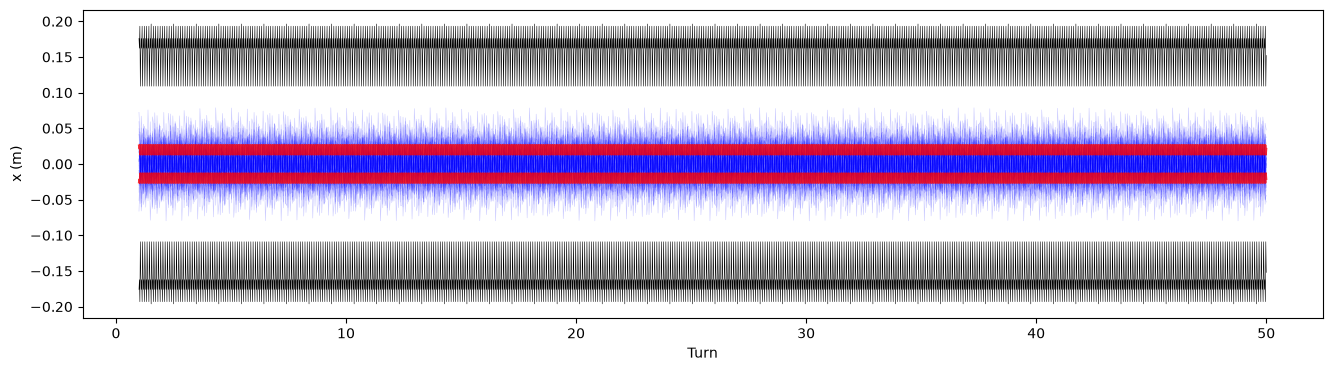

In [6]:
fig, ax = plt.subplots(1, figsize=(16,4))
lw=0.4
ax.plot(np.linspace(1,n_turns,len(x_xsuite)), x_xsuite, lw=lw, c='b', alpha=0.2, label='Xsuite')
#ax.plot(np.linspace(1,n_turns,len(x_xsuite)), x_mycode, lw=lw, c='b', label='My code')
#ax.plot(np.linspace(1,n_turns,len(x_xsuite)), x_mycode_ind, lw=lw, c='r', label='My code')

ax.plot(np.linspace(1,n_turns,n_turns*n_spacecharge_elements), np.tile(Lx,n_turns), lw=lw, c='k', label='My code')
ax.plot(np.linspace(1,n_turns,n_turns*n_spacecharge_elements), np.tile(-Lx,n_turns), lw=lw, c='k', label='My code')
#ax.fill_between(np.linspace(1,n_turns,n_turns*n_spacecharge_elements), np.tile(sigma_x,n_turns), np.tile(-sigma_x,n_turns), color='r', alpha=0.8)
ax.plot(np.linspace(1,n_turns,n_turns*n_spacecharge_elements), np.tile(sigma_x,n_turns), color='r', alpha=0.8)
ax.plot(np.linspace(1,n_turns,n_turns*n_spacecharge_elements), np.tile(-sigma_x,n_turns), color='r', alpha=0.8)
ax.set_xlabel('Turn')
ax.set_ylabel('x (m)')
plt.show()

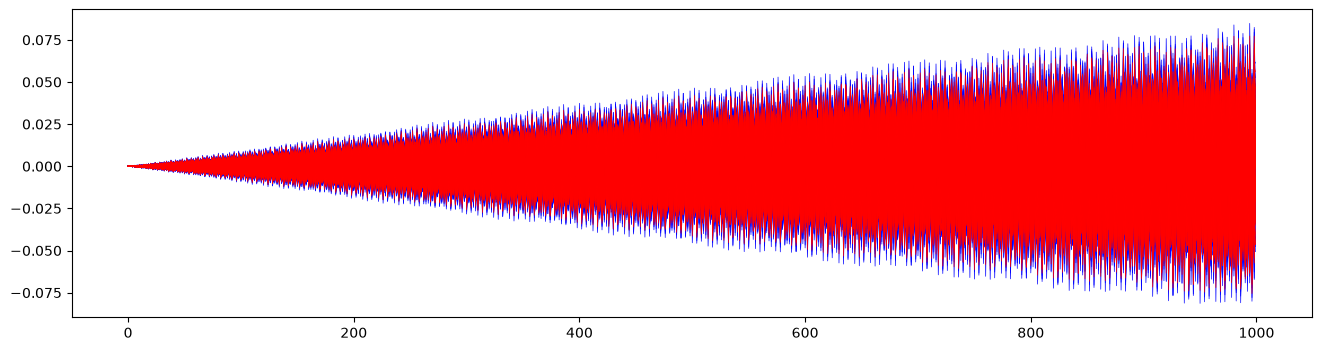

In [7]:
fig, ax = plt.subplots(1, figsize=(16,4))
lw=0.5
START=None
END=None
ax.plot((x_mycode-x_xsuite)[START:END], lw=lw, c='b', label='Xsuite')
ax.plot((x_mycode_ind-x_xsuite)[START:END], lw=lw, c='r', label='My code')
#ax.legend()
plt.show()

In [8]:
sc_mycode = [
    el for name, el in line_mycode.element_dict.items()
    if 'SpaceCharge' in type(el).__name__
]
sc_mycode_ind = [
    el for name, el in line_mycode_ind.element_dict.items()
    if 'SpaceCharge' in type(el).__name__
]

i=1
print(sc_mycode[i])
print('----------------------------------')
print(sc_mycode_ind[i])

SpaceChargeFree(element_length=3.27, line_density=6.12e+09, mean_x=7e-11, mean_y=-1.01e-25, sigma_x=0.0216, sigma_y=0.0323, shift_x=0, shift_y=0, shift_s=0, rot_s_rad=0, rot_x_rad=0, rot_y_rad=0, rot_s_rad_no_frame=0, rot_shift_anchor=0)
----------------------------------
SpaceChargeRectangular(element_length=3.27, line_density=6.12e+09, mean_x=7e-11, mean_y=-1.01e-25, sigma_x=0.0216, sigma_y=0.0323, shift_x=0, shift_y=0, shift_s=0, rot_s_rad=0, rot_x_rad=0, rot_y_rad=0, rot_s_rad_no_frame=0, rot_shift_anchor=0, width=0.162, height=0.183, nx=np.int64(0), ny=np.int64(0))


In [9]:
i=1
line=line_xsuite.copy()
particle_mycode = line.build_particles(x=2e-5, y=2e-5, px=0, py=0)
sc_mycode[i].track(particle_mycode)
particle_mycode_ind = line.build_particles(x=2e-5, y=2e-5, px=0, py=0)
sc_mycode_ind[i].track(particle_mycode_ind)
print((particle_mycode.px - particle_mycode_ind.px)/(particle_mycode.px + particle_mycode_ind.px))
print((particle_mycode.py - particle_mycode_ind.py)/(particle_mycode.py + particle_mycode_ind.py))


Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
[-0.00631718]
[0.00961014]


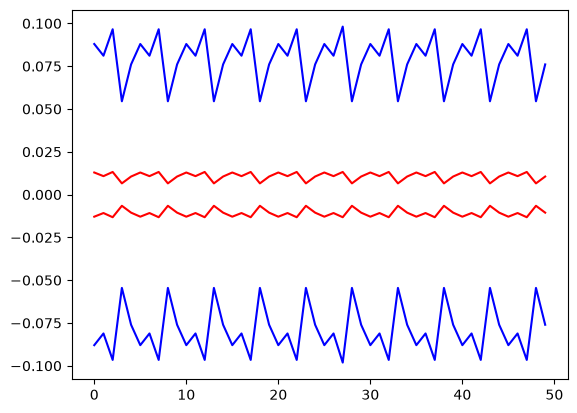

In [10]:
sigma_x = []
Lx = []
for element in sc_mycode_ind:
    sigma_x.append(element.sigma_x)
    Lx.append(element.width)

sigma_x = np.array(sigma_x)
Lx = np.array(Lx)
plt.plot(sigma_x/2, c='r')
plt.plot(-sigma_x/2, c='r')
plt.plot(Lx/2, c='b')
plt.plot(-Lx/2, c='b')

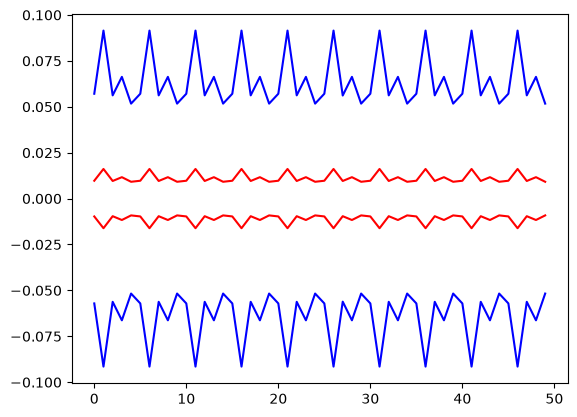

In [11]:
sigma_x = []
Lx = []
for element in sc_mycode_ind:
    sigma_x.append(element.sigma_y)
    Lx.append(element.height)

sigma_x = np.array(sigma_x)
Lx = np.array(Lx)
plt.plot(sigma_x/2, c='r')
plt.plot(-sigma_x/2, c='r')
plt.plot(Lx/2, c='b')
plt.plot(-Lx/2, c='b')